Purpose of this paper was to determine the best version of the LSTM recurrent structure. Previously there were several different variations that were used as a control. This paper aimed to standardize that. This implementation is not the same generic LSTM from 1997, rather it has two additions: forget gate and peephole connections.

LSTM components (belt = cell state analogy):

Block input — candidate new info proposed for the belt; not yet gated.

Input gate — controls how much of the candidate gets written onto the belt.

Forget gate — controls how much of the existing belt content gets erased before writing.

Cell (CEC) — the belt itself: (forget gate × old value) + (input gate × new candidate).

Output gate — controls how much of the belt's contents gets exposed as output. Key nuance: the cell can hold info without exposing it — memory ≠ current output.

Peepholes — let gates see the cell's own current contents (not just input/previous output) when deciding to write/forget/output. Helps learn precise timing (e.g., "hold this value for exactly N steps").

Sigmoid vs. tanh: Gates use sigmoid (range 0–1) since they act as proportions/switches ("let through 30%"). Block input/output use tanh (range −1 to 1) since they carry actual signed content. Activation choice matches each component's role: gating needs a fraction, content needs sign.

This reads as:
cell = (new candidate value) × (input gate) + (old cell value) × (forget gate)
$c^t = z^t \odot i^t + c^{t-1} \odot f^t$


In [2]:
#finish lstm, familiarize with git, github, ssh gpu resources
#methodology, experimentation&results
#https://interpretabledeeplearning.github.io/tutorials/tutorial_aaai2026/

# Cell 1: Imports & Setup
# Purpose: bring in the libraries we need (PyTorch for tensors/autograd,
# matplotlib for the comparison plots later) and lock down reproducibility
# by setting a random seed and picking the compute device (GPU if available).
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Reproducibility: same seed -> same synthetic data & weight init each run,
# so differences between Vanilla/CIFG/NP are due to the architecture change,
# not random noise (same controlled-ablation logic from the paper).

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")



Using device: cuda


In [3]:
# Cell 2: Copy-Task Data Generation
# Purpose: generate synthetic sequences for the "copy task" — the model sees
# a short sequence of random tokens, then a run of blank/delay steps, then a
# delimiter, and must reproduce the original tokens right after the delimiter.
# This task specifically stresses long-range memory: the only way to get the
# reproduction right is to carry the original tokens across the entire delay
# untouched, which is exactly what the cell state / CEC is supposed to enable.

# Vocabulary: tokens 0..(NUM_TOKENS-1) are the "content" symbols to copy.
# BLANK is what fills the delay period. DELIM signals "now start copying."

NUM_TOKENS = 8
BLANK = NUM_TOKENS
DELIM = NUM_TOKENS + 1
VOCAB_SIZE = NUM_TOKENS + 2

def generate_copy_batch(batch_size, seq_len, delay, device=device):
    """
    Builds a batch of copy-task sequences.

    Layout of each sequence (length = seq_len + delay + seq_len):
      [random tokens] + [blank filler, length=delay] + [delimiter] + [blanks, length=seq_len-1]
    Target: predict blank during the first (seq_len + delay) steps,
            then predict the original tokens in order after the delimiter.

    Returns:
      inputs:  (batch_size, total_len) long tensor of token indices
      targets: (batch_size, total_len) long tensor of target token indices
    """
    total_len = seq_len + delay + seq_len + 1
    # Random content tokens to be copied
    content = torch.randint(0, NUM_TOKENS, (batch_size, seq_len))

    inputs = torch.full((batch_size, total_len), BLANK, dtype=torch.long)
    targets = torch.full((batch_size, total_len), BLANK, dtype=torch.long)

    # Place the content tokens at the start of the input
    inputs[:, :seq_len] = content

    # Place the delimiter right after the delay period
    delim_pos = seq_len + delay
    inputs[:, delim_pos] = DELIM

    # Targets: model should output the content tokens starting right after the delimiter
    targets[:, delim_pos + 1 : delim_pos + 1 + seq_len] = content

    return inputs.to(device), targets.to(device)

# Quick sanity check — print one example so you can see the layout
demo_in, demo_tgt = generate_copy_batch(batch_size=1, seq_len=5, delay=10)
print("Input: ", demo_in[0].tolist())
print("Target:", demo_tgt[0].tolist())


Input:  [6, 3, 4, 6, 2, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8]
Target: [8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 6, 3, 4, 6, 2]


In [4]:
# Cell 3: Vanilla LSTM Cell (explicit gate equations, no nn.LSTM)
# Purpose: implement the forward pass from Section II by hand — block input,
# input/forget/output gates (with peepholes), and the cell update — so every
# equation from the paper is visible as actual code rather than hidden inside
# a black-box nn.LSTM call. This is the baseline all variants are compared to.

class VanillaLSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size):
    super().__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size

    # Input weights: W_z, W_i, W_f, W_o  (map x^t -> each component)
    # Recurrent weights: R_z, R_i, R_f, R_o  (map y^{t-1} -> each component)
    # We store each as a single Linear layer covering both, for convenience:
    # combined_input = concat(x^t, y^{t-1}), one Linear per component.

    self.block_input = nn.Linear(input_size + hidden_size, hidden_size)
    self.input_gate = nn.Linear(input_size + hidden_size, hidden_size)
    self.forget_gate = nn.Linear(input_size + hidden_size, hidden_size)
    self.output_gate = nn.Linear(input_size + hidden_size, hidden_size)

    # Peephole weights: p_i, p_f, p_o -- one learnable vector per gate,
    # elementwise-multiplied with the cell state (not a full matrix).

    self.p_i = nn.Parameter(torch.zeros(hidden_size))
    self.p_f = nn.Parameter(torch.zeros(hidden_size))
    self.p_o = nn.Parameter(torch.zeros(hidden_size))

  def forward(self, x_t, y_prev, c_prev):
        """
        x_t:    (batch, input_size)   current input
        y_prev: (batch, hidden_size)  previous block output y^{t-1}
        c_prev: (batch, hidden_size)  previous cell state c^{t-1}
        Returns: y_t, c_t  (both (batch, hidden_size))
        """

        combined = torch.cat([x_t, y_prev], dim = 1)

        # Block input (candidate): z_bar = W_z x^t + R_z y^{t-1} + b_z, then tanh
        z_t = torch.tanh(self.block_input(combined))

        # Input gate: peephole uses c_prev (c^{t-1}, since c^t doesn't exist yet)
        i_t = torch.sigmoid(self.input_gate(combined) + self.p_i * c_prev)

        # Forget gate: same peephole convention
        f_t = torch.sigmoid(self.forget_gate(combined) + self.p_f * c_prev)

        # Cell update: c^t = z^t ⊙ i^t + c^{t-1} ⊙ f^t   (the CEC)
        c_t = z_t * i_t + c_prev * f_t

        # Output gate: peephole uses c_t (current cell state, just computed)
        o_t = torch.sigmoid(self.output_gate(combined) + self.p_o * c_t)

        #Block output: y^t = h(c^t) ⊙ o^t
        y_t = torch.tanh(c_t) * o_t

        return y_t, c_t

# Quick sanity check: run one step with random input and zero initial state
test_cell = VanillaLSTMCell(input_size = VOCAB_SIZE, hidden_size = 16).to(device)
x_test = torch.randn(4, VOCAB_SIZE).to(device)
y0 = torch.zeros(4,16).to(device)
c0 = torch.zeros(4,16).to(device)
y1, c1 = test_cell(x_test, y0, c0)
print("y_t shape:", y1.shape, "| c_t shape:", c1.shape)


y_t shape: torch.Size([4, 16]) | c_t shape: torch.Size([4, 16])


In [5]:
# Cell 4: CIFG LSTM Cell (Coupled Input and Forget Gate)
# Purpose: same as VanillaLSTMCell, but the forget gate is not learned
# independently -- it's tied to the input gate via f^t = 1 - i^t. This is
# the paper's CIFG variant (equivalent to how GRU couples these gates).
# Everything else (block input, output gate, peepholes, cell update) is
# identical to Vanilla -- this isolates gate-coupling as the one variable
# being changed, per the controlled-ablation logic.

class CIFGLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size

        self.block_input = nn.Linear(input_size + hidden_size, hidden_size)
        self.input_gate   = nn.Linear(input_size + hidden_size, hidden_size)
        # Note: no separate forget_gate Linear layer -- CIFG has no
        # independent forget gate weights at all, since f^t is derived
        # directly from i^t rather than learned.
        self.output_gate  = nn.Linear(input_size + hidden_size, hidden_size)

        # Peephole weights: still present (vanilla keeps peepholes, and CIFG
        # only changes the gate-coupling, not the peephole question).
        self.p_i = nn.Parameter(torch.zeros(hidden_size))
        self.p_f = nn.Parameter(torch.zeros(hidden_size))
        self.p_o = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x_t, y_prev, c_prev):
        """
        x_t:    (batch, input_size)   current input
        y_prev: (batch, hidden_size)  previous block output y^{t-1}
        c_prev: (batch, hidden_size)  previous cell state c^{t-1}
        Returns: y_t, c_t  (both (batch, hidden_size))
        """
        combined = torch.cat([x_t, y_prev], dim=1)

        # Block input (candidate)
        z_t = torch.tanh(self.block_input(combined))

        # Input gate: computed exactly as in Vanilla
        i_t = torch.sigmoid(self.input_gate(combined) + self.p_i * c_prev)

        # Forget gate: coupled to the input gate -- f^t = 1 - i^t
        # (still uses p_f as a peephole-style scaling on the coupling,
        # but note the paper's CIFG defines f^t purely as 1 - i^t;
        # we keep p_f unused here to stay faithful to that definition)
        f_t = 1.0 - i_t

        # Cell update: identical structure to Vanilla
        c_t = z_t * i_t + c_prev * f_t

        # Output gate
        o_t = torch.sigmoid(self.output_gate(combined) + self.p_o * c_t)

        # Block output
        y_t = torch.tanh(c_t) * o_t

        return y_t, c_t

# Quick sanity check
test_cifg = CIFGLSTMCell(input_size=VOCAB_SIZE, hidden_size=16).to(device)
x_test = torch.randn(4, VOCAB_SIZE).to(device)
y0 = torch.zeros(4, 16).to(device)
c0 = torch.zeros(4, 16).to(device)
y1, c1 = test_cifg(x_test, y0, c0)
print("y_t shape:", y1.shape, "| c_t shape:", c1.shape)

y_t shape: torch.Size([4, 16]) | c_t shape: torch.Size([4, 16])


In [6]:
# Cell 5: NP LSTM Cell (No Peepholes)
# Purpose: same as VanillaLSTMCell, but the peephole connections are removed
# entirely -- gates no longer see the cell state directly, only the current
# input and previous output (same information the block input itself uses).
# Everything else (independent input/forget gates, cell update, output
# activation) is identical to Vanilla -- this isolates "removing peepholes"
# as the one variable being changed, per the controlled-ablation logic.

class NPLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size

        self.block_input = nn.Linear(input_size + hidden_size, hidden_size)
        self.input_gate   = nn.Linear(input_size + hidden_size, hidden_size)
        self.forget_gate  = nn.Linear(input_size + hidden_size, hidden_size)
        self.output_gate  = nn.Linear(input_size + hidden_size, hidden_size)

        # No peephole parameters at all -- this is the entire change vs. Vanilla.
        # (No self.p_i, self.p_f, self.p_o here.)

    def forward(self, x_t, y_prev, c_prev):
        """
        x_t:    (batch, input_size)   current input
        y_prev: (batch, hidden_size)  previous block output y^{t-1}
        c_prev: (batch, hidden_size)  previous cell state c^{t-1}
        Returns: y_t, c_t  (both (batch, hidden_size))
        """
        combined = torch.cat([x_t, y_prev], dim=1)

        # Block input (candidate) -- identical to Vanilla
        z_t = torch.tanh(self.block_input(combined))

        # Input gate: no peephole term added
        i_t = torch.sigmoid(self.input_gate(combined))

        # Forget gate: no peephole term added, independently learned (unlike CIFG)
        f_t = torch.sigmoid(self.forget_gate(combined))

        # Cell update: identical structure to Vanilla
        c_t = z_t * i_t + c_prev * f_t

        # Output gate: no peephole term added
        o_t = torch.sigmoid(self.output_gate(combined))

        # Block output: identical to Vanilla
        y_t = torch.tanh(c_t) * o_t

        return y_t, c_t

# Quick sanity check
test_np = NPLSTMCell(input_size=VOCAB_SIZE, hidden_size=16).to(device)
x_test = torch.randn(4, VOCAB_SIZE).to(device)
y0 = torch.zeros(4, 16).to(device)
c0 = torch.zeros(4, 16).to(device)
y1, c1 = test_np(x_test, y0, c0)
print("y_t shape:", y1.shape, "| c_t shape:", c1.shape)

y_t shape: torch.Size([4, 16]) | c_t shape: torch.Size([4, 16])


In [7]:
# Cell 6: Model Wrapper + Shared Training Loop
# Purpose: wrap any of our LSTM cell classes into a full sequence model
# (embedding -> LSTM cell stepped over time -> output projection), and define
# ONE training function used identically for Vanilla/CIFG/NP. Using the same
# function, same hyperparameters, and same data-generation seed logic for all
# three is what makes the comparison a true controlled ablation -- the only
# thing that differs between runs is which cell class is plugged in.

class SequenceModel(nn.Module):
    def __init__(self, cell_class, vocab_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        # Embedding: turns integer token indices into dense vectors,
        # which is what our cells expect as x_t (rather than raw integers).
        self.embedding = nn.Embedding(vocab_size, vocab_size)
        self.cell = cell_class(input_size=vocab_size, hidden_size=hidden_size)
        # Output projection: turns each y_t into a distribution over the vocab
        self.output_proj = nn.Linear(hidden_size, vocab_size)

    def forward(self, inputs):
        """
        inputs: (batch, seq_len) long tensor of token indices
        Returns: logits, shape (batch, seq_len, vocab_size)
        """
        batch_size, seq_len = inputs.shape
        y_t = torch.zeros(batch_size, self.hidden_size, device=inputs.device)
        c_t = torch.zeros(batch_size, self.hidden_size, device=inputs.device)

        embedded = self.embedding(inputs)  # (batch, seq_len, vocab_size)

        outputs = []
        for t in range(seq_len):
            x_t = embedded[:, t, :]              # (batch, vocab_size)
            y_t, c_t = self.cell(x_t, y_t, c_t)   # one step through the LSTM cell
            outputs.append(self.output_proj(y_t))  # (batch, vocab_size)

        logits = torch.stack(outputs, dim=1)  # (batch, seq_len, vocab_size)
        return logits


def train_model(cell_class, seq_len, delay, hidden_size=32,
                 num_steps=300, batch_size=64, lr=1e-3, seed=SEED):
    """
    Trains one SequenceModel (using the given cell_class) on the copy task.
    Returns a list of loss values, one per training step, for plotting.
    """
    torch.manual_seed(seed)  # same init + same data stream across variants

    model = SequenceModel(cell_class, VOCAB_SIZE, hidden_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    loss_history = []
    for step in range(num_steps):
        inputs, targets = generate_copy_batch(batch_size, seq_len, delay)

        logits = model(inputs)  # (batch, seq_len, vocab_size)

        # Cross-entropy expects (batch*seq_len, vocab_size) vs (batch*seq_len,)
        loss = F.cross_entropy(
            logits.reshape(-1, VOCAB_SIZE),
            targets.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

        if step % 50 == 0:
            print(f"  step {step:4d} | loss {loss.item():.4f}")

    return loss_history, model

In [8]:
# Cell 7: Train Vanilla LSTM
# Purpose: run the shared training loop with VanillaLSTMCell plugged in.
# This is our baseline run -- CIFG and NP will be compared against this.

SEQ_LEN = 5
DELAY = 10

print("Training Vanilla LSTM...")
vanilla_losses, vanilla_model = train_model(
    cell_class=VanillaLSTMCell,
    seq_len=SEQ_LEN,
    delay=DELAY,
)
print("Done.")

Training Vanilla LSTM...
  step    0 | loss 2.3338
  step   50 | loss 1.4278
  step  100 | loss 1.0722
  step  150 | loss 0.6427
  step  200 | loss 0.5762
  step  250 | loss 0.5466
Done.


In [9]:
# Cell 8: Train CIFG LSTM
# Purpose: same training procedure, same hyperparameters, same seed --
# only the cell class differs. This isolates gate-coupling as the one
# variable being tested against the Vanilla baseline.

print("Training CIFG LSTM...")
cifg_losses, cifg_model = train_model(
    cell_class=CIFGLSTMCell,
    seq_len=SEQ_LEN,
    delay=DELAY,
)
print("Done.")

Training CIFG LSTM...
  step    0 | loss 2.2827
  step   50 | loss 1.3928
  step  100 | loss 1.1254
  step  150 | loss 0.7944
  step  200 | loss 0.5985
  step  250 | loss 0.5567
Done.


In [10]:
# Cell 9: Train NP LSTM
# Purpose: same training procedure, same hyperparameters, same seed --
# only the cell class differs. This isolates peephole removal as the one
# variable being tested against the Vanilla baseline.

print("Training NP (No Peepholes) LSTM...")
np_losses, np_model = train_model(
    cell_class=NPLSTMCell,
    seq_len=SEQ_LEN,
    delay=DELAY,
)
print("Done.")

Training NP (No Peepholes) LSTM...
  step    0 | loss 2.3338
  step   50 | loss 1.4265
  step  100 | loss 1.1089
  step  150 | loss 0.6683
  step  200 | loss 0.5812
  step  250 | loss 0.5491
Done.


/tmp/ipykernel_1221/223858702.py:18: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_comparison.png", dpi=200, bbox_inches="tight")
/tmp/ipykernel_1221/223858702.py:18: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_comparison.png", dpi=200, bbox_inches="tight")
/tmp/ipykernel_1221/223858702.py:18: UserWarning: Glyph 128123 (\N{GHOST}) missing from font(s) DejaVu Sans.
  plt.savefig("loss_comparison.png", dpi=200, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Gly

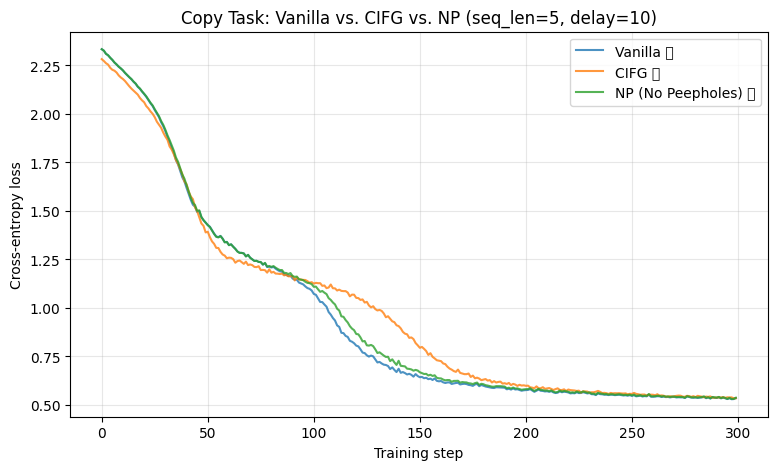

Final loss -- Vanilla: 0.5351
Final loss -- CIFG:    0.5344
Final loss -- NP:      0.5369


In [11]:
# Cell 10: Comparison Plot
# Purpose: overlay the three loss curves to visually compare how fast/well
# Vanilla, CIFG, and NP each learn the copy task. Per the paper's findings,
# we'd expect CIFG and NP to track Vanilla closely (no significant harm from
# either simplification) -- this plot is where you get to check that against
# your own trained models rather than just taking the paper's word for it.

plt.figure(figsize=(9, 5))
plt.plot(vanilla_losses, label="Vanilla 🧠", alpha=0.8)
plt.plot(cifg_losses, label="CIFG 🔗", alpha=0.8)
plt.plot(np_losses, label="NP (No Peepholes) 👻", alpha=0.8)

plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title(f"Copy Task: Vanilla vs. CIFG vs. NP (seq_len={SEQ_LEN}, delay={DELAY})")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("loss_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Print final losses for a quick numeric comparison alongside the plot
print(f"Final loss -- Vanilla: {vanilla_losses[-1]:.4f}")
print(f"Final loss -- CIFG:    {cifg_losses[-1]:.4f}")
print(f"Final loss -- NP:      {np_losses[-1]:.4f}")

/tmp/ipykernel_1221/1387483572.py:53: UserWarning: Glyph 128682 (\N{DOOR}) missing from font(s) DejaVu Sans.
  plt.savefig("forget_gate.png", dpi=200, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128682 (\N{DOOR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


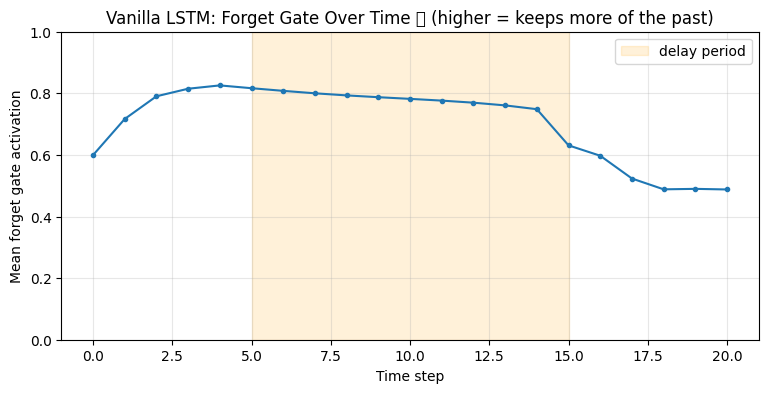

Input sequence: [6, 3, 1, 6, 4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8]


In [12]:
# Cell 11 (Optional): Forget Gate Inspection
# Purpose: directly visualize the CEC in action -- pull out the forget gate's
# activation values over time for one example sequence, and check whether it
# stays close to 1 during the delay period (positions seq_len..seq_len+delay),
# which is the behavior theory predicts the network needs to learn in order
# to preserve the content tokens across the gap.

def inspect_forget_gate(model, seq_len, delay):
    model.eval()
    inputs, targets = generate_copy_batch(batch_size=1, seq_len=seq_len, delay=delay)

    batch_size, total_len = inputs.shape
    hidden_size = model.hidden_size
    y_t = torch.zeros(batch_size, hidden_size, device=device)
    c_t = torch.zeros(batch_size, hidden_size, device=device)
    embedded = model.embedding(inputs)

    forget_gate_means = []
    with torch.no_grad():
        for t in range(total_len):
            x_t = embedded[:, t, :]
            combined = torch.cat([x_t, y_t], dim=1)

            # Recompute the forget gate the same way the cell does internally.
            # (Vanilla/NP have their own forget_gate layer; CIFG derives f_t
            # from i_t instead -- handle both cases.)
            if hasattr(model.cell, "forget_gate"):
                if hasattr(model.cell, "p_f"):
                    f_t = torch.sigmoid(model.cell.forget_gate(combined) + model.cell.p_f * c_t)
                else:
                    f_t = torch.sigmoid(model.cell.forget_gate(combined))
            else:
                i_t = torch.sigmoid(model.cell.input_gate(combined) + model.cell.p_i * c_t)
                f_t = 1.0 - i_t

            forget_gate_means.append(f_t.mean().item())
            y_t, c_t = model.cell(x_t, y_t, c_t)

    model.train()
    return forget_gate_means, inputs[0].tolist()

fg_vanilla, seq_vanilla = inspect_forget_gate(vanilla_model, SEQ_LEN, DELAY)

plt.figure(figsize=(9, 4))
plt.plot(fg_vanilla, marker="o", markersize=3)
plt.axvspan(SEQ_LEN, SEQ_LEN + DELAY, alpha=0.15, color="orange", label="delay period")
plt.xlabel("Time step")
plt.ylabel("Mean forget gate activation")
plt.title("Vanilla LSTM: Forget Gate Over Time 🚪 (higher = keeps more of the past)")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("forget_gate.png", dpi=200, bbox_inches="tight")
plt.show()

print("Input sequence:", seq_vanilla)